# Loading the IMDB Dataset
The IMDB dataset contains movie reviews classified as either positive or negative. The dataset is divided into training and test sets, with an equal proportion of positive and negative reviews. For this analysis, the data is limited to the 10,000 most frequently occurring words.

In [13]:
from tensorflow.keras.datasets import imdb

(train_data, train_labels), (test_data, test_labels) = imdb.load_data(num_words=10000)

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


# Examining the Training Data
Each movie review has already been converted into a sequence of integers. Each integer represents a particular word in the IMDB vocabulary. The corresponding labels are either 0 or 1, where 0 represents a negative review and 1 represents a positive review.

In [23]:
train_data[0]

[1,
 14,
 22,
 16,
 43,
 530,
 973,
 1622,
 1385,
 65,
 458,
 4468,
 66,
 3941,
 4,
 173,
 36,
 256,
 5,
 25,
 100,
 43,
 838,
 112,
 50,
 670,
 2,
 9,
 35,
 480,
 284,
 5,
 150,
 4,
 172,
 112,
 167,
 2,
 336,
 385,
 39,
 4,
 172,
 4536,
 1111,
 17,
 546,
 38,
 13,
 447,
 4,
 192,
 50,
 16,
 6,
 147,
 2025,
 19,
 14,
 22,
 4,
 1920,
 4613,
 469,
 4,
 22,
 71,
 87,
 12,
 16,
 43,
 530,
 38,
 76,
 15,
 13,
 1247,
 4,
 22,
 17,
 515,
 17,
 12,
 16,
 626,
 18,
 2,
 5,
 62,
 386,
 12,
 8,
 316,
 8,
 106,
 5,
 4,
 2223,
 5244,
 16,
 480,
 66,
 3785,
 33,
 4,
 130,
 12,
 16,
 38,
 619,
 5,
 25,
 124,
 51,
 36,
 135,
 48,
 25,
 1415,
 33,
 6,
 22,
 12,
 215,
 28,
 77,
 52,
 5,
 14,
 407,
 16,
 82,
 2,
 8,
 4,
 107,
 117,
 5952,
 15,
 256,
 4,
 2,
 7,
 3766,
 5,
 723,
 36,
 71,
 43,
 530,
 476,
 26,
 400,
 317,
 46,
 7,
 4,
 2,
 1029,
 13,
 104,
 88,
 4,
 381,
 15,
 297,
 98,
 32,
 2071,
 56,
 26,
 141,
 6,
 194,
 7486,
 18,
 4,
 226,
 22,
 21,
 134,
 476,
 26,
 480,
 5,
 144,
 30,
 5535,
 18,

In [24]:
train_labels[0]

np.int64(1)

In [25]:
max([max(sequence)for sequence in train_data])

9999

# Preparing the Data
Movie reviews were converted into a numerical format that could be processed by the neural network. The model considered the presence or absence of the 10,000 most frequently occurring words.

In [29]:
import numpy as np

def vectorize_sequences(sequences, dimension=10000):
  results = np.zeros((len(sequences), dimension))
  for i, sequence in enumerate(sequences):
    results[i, sequence] = 1.
  return results

x_train = vectorize_sequences(train_data)
x_test = vectorize_sequences(test_data)

In [30]:
x_train[0]

array([0., 1., 1., ..., 0., 0., 0.])

In [31]:
y_train = np.asarray(train_labels).astype("float32")
y_test = np.asarray(test_labels).astype("float32")

# Creating the Validation Set
The original training data was divided into 15,000 training observations and 10,000 validation observations. Validation performance was used to compare alternative neural network configurations.

In [32]:
x_val = x_train[:10000]
partial_x_train = x_train[10000:]

y_val = y_train[:10000]
partial_y_train = y_train[10000:]

# Baseline Neural Network
The initial model serves as the baseline for comparison with the alternative models tested later in the analysis. The baseline network contains two hidden layers with 16 units each and uses the ReLU activation function. The output layer contains one unit with a sigmoid activation function because the goal is to classify each review as positive or negative.

In [33]:
from tensorflow import keras
from tensorflow.keras import layers

model = keras.Sequential([
    layers.Dense(16, activation="relu"),
    layers.Dense(16, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

In [34]:
model.compile(
    optimizer="rmsprop",
    loss="binary_crossentropy",
    metrics=["accuracy"])

# Training the Baseline Model
The baseline model was trained for 20 epochs using a batch size of 512. Training and validation performance were recorded after each epoch to determine when the model's performance on unseen validation data stopped improving.

In [36]:
history = model.fit(
    partial_x_train,
    partial_y_train,
    epochs=20,
    batch_size=512,
    validation_data=(x_val, y_val)
)

Epoch 1/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 6s 139ms/step - accuracy: 0.7849 - loss: 0.5276 - val_accuracy: 0.8623 - val_loss: 0.4076
Epoch 2/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.8935 - loss: 0.3294 - val_accuracy: 0.8608 - val_loss: 0.3513
Epoch 3/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.9174 - loss: 0.2484 - val_accuracy: 0.8694 - val_loss: 0.3201
Epoch 4/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.9337 - loss: 0.1983 - val_accuracy: 0.8902 - val_loss: 0.2745
Epoch 5/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.9452 - loss: 0.1661 - val_accuracy: 0.8888 - val_loss: 0.2754
Epoch 6/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.9563 - loss: 0.1381 - val_accuracy: 0.8842 - val_loss: 0.2856
Epoch 7/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.9635 - loss: 0.1178 - val_accuracy: 0.8838 - val_loss: 0.3053
Epoch 8/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.9702 - loss: 0.0999 - val_accuracy: 0.8841 - 

In [37]:
history_dict = history.history
history_dict.keys()

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])

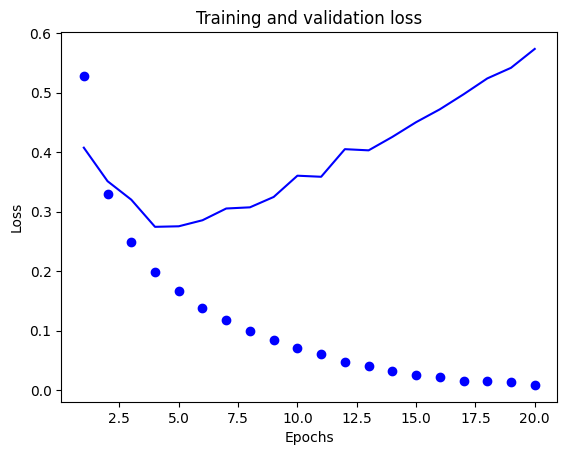

In [38]:
import matplotlib.pyplot as plt

history_dict = history.history
loss_values = history_dict["loss"]
val_loss_values = history_dict["val_loss"]
epochs = range(1, len(loss_values) + 1)

plt.plot(epochs, loss_values, "bo", label="Training loss")
plt.plot(epochs, val_loss_values, "b", label="Validation loss")
plt.title("Training and validation loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend

plt.show()

# Baseline Loss Results
Training loss continued to decrease throughout the 20 epochs, indicating that the model continued to fit the training data more closely. However, validation loss reached its lowest point around epoch 4 and then began to increase. This indicates that the model began to overfit after approximately four epochs.

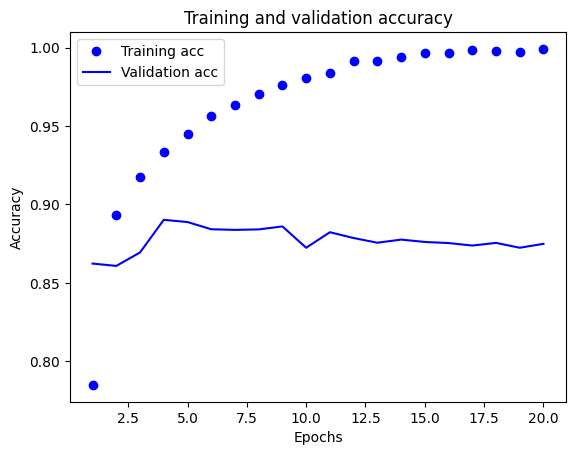

In [39]:
plt.clf()

acc = history_dict["accuracy"]
val_acc = history_dict["val_accuracy"]

plt.plot(epochs, acc, "bo", label="Training acc")
plt.plot(epochs, val_acc, "b", label="Validation acc")
plt.title("Training and validation accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

plt.show()

# Baseline Accuracy Results
Training accuracy continued to increase and approached 100%, while validation accuracy reached its highest level much earlier and did not continue improving. This difference between training and validation performance provides additional evidence of overfitting. The baseline model achieved its highest validation accuracy of 89.02% at epoch 4. Training accuracy continued to increase after epoch 4, while validation accuracy did not show continued improvement. Combined with the increase in validation loss after approximately epoch 4, this suggests that additional training caused the model to overfit the training data.

In [40]:
max(history_dict["val_accuracy"])

0.8902000188827515

In [42]:
history_dict["val_accuracy"].index(max(history_dict["val_accuracy"])) + 1

4

# Experiment 1: Number of Hidden Layers
The baseline neural network contains two hidden layers with 16 units each. To examine how the depth of the network affects model performance, models with one and three hidden layers will be compared with the two-layer baseline. All other model settings will remain unchanged so that the effect of changing the number of hidden layers can be evaluated.

In [45]:
model_1 = keras.Sequential([
    layers.Dense(16, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

model_1.compile(
    optimizer="rmsprop",
    loss="binary_crossentropy",
    metrics=["accuracy"])

In [46]:
history_1 = model_1.fit(
    partial_x_train,
    partial_y_train,
    epochs=20,
    batch_size=512,
    validation_data=(x_val, y_val)
)

Epoch 1/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 4s 86ms/step - accuracy: 0.7815 - loss: 0.5117 - val_accuracy: 0.8655 - val_loss: 0.3942
Epoch 2/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.8953 - loss: 0.3305 - val_accuracy: 0.8832 - val_loss: 0.3235
Epoch 3/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.9145 - loss: 0.2625 - val_accuracy: 0.8808 - val_loss: 0.3025
Epoch 4/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.9286 - loss: 0.2198 - val_accuracy: 0.8896 - val_loss: 0.2838
Epoch 5/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.9378 - loss: 0.1931 - val_accuracy: 0.8887 - val_loss: 0.2769
Epoch 6/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.9477 - loss: 0.1692 - val_accuracy: 0.8839 - val_loss: 0.2860
Epoch 7/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.9530 - loss: 0.1534 - val_accuracy: 0.8857 - val_loss: 0.2810
Epoch 8/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.9578 - loss: 0.1385 - val_accuracy: 0.8857 - v

In [47]:
max(history_1.history["val_accuracy"])

0.8895999789237976

In [48]:
history_1.history["val_accuracy"].index(max(history_1.history["val_accuracy"])) + 1

4

In [49]:
model_3 = keras.Sequential([
    layers.Dense(16, activation="relu"),
    layers.Dense(16, activation="relu"),
    layers.Dense(16, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

model_3.compile(
    optimizer="rmsprop",
    loss="binary_crossentropy",
    metrics=["accuracy"])

In [50]:
history_3 = model_3.fit(
    partial_x_train,
    partial_y_train,
    epochs=20,
    batch_size=512,
    validation_data=(x_val, y_val)
)

Epoch 1/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 5s 105ms/step - accuracy: 0.7721 - loss: 0.5413 - val_accuracy: 0.8572 - val_loss: 0.4025
Epoch 2/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.8907 - loss: 0.3191 - val_accuracy: 0.8848 - val_loss: 0.3009
Epoch 3/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.9233 - loss: 0.2234 - val_accuracy: 0.8812 - val_loss: 0.2967
Epoch 4/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.9382 - loss: 0.1789 - val_accuracy: 0.8864 - val_loss: 0.2801
Epoch 5/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.9472 - loss: 0.1478 - val_accuracy: 0.8846 - val_loss: 0.3010
Epoch 6/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.9622 - loss: 0.1146 - val_accuracy: 0.8849 - val_loss: 0.3112
Epoch 7/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.9659 - loss: 0.1034 - val_accuracy: 0.8815 - val_loss: 0.3409
Epoch 8/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.9745 - loss: 0.0828 - val_accuracy: 0.8791 - 

In [51]:
max(history_3.history["val_accuracy"])

0.8863999843597412

In [52]:
history_3.history["val_accuracy"].index(max(history_3.history["val_accuracy"])) + 1

4

# Hidden Layer Results
Changing the number of hidden layers produced relatively small differences in validation accuracy. The one-hidden-layer model achieved a best validation accuracy of 88.96%, compared with 89.02% for the two-hidden-layer baseline. Increasing the network to three hidden layers resulted in a slightly lower best validation accuracy of 88.64%. All three models achieved their highest validation accuracy at epoch 4. These results indicate that increasing the depth of the network did not improve validation performance for this dataset.

# Experiment 2: Number of Hidden Units
The baseline model uses 16 units in each hidden layer. To examine how the size of the hidden layers affects model performance, models with 32 and 64 units per hidden layer will be compared with the 16-unit baseline. The number of hidden layers and the other model settings will remain unchanged so that the effect of changing the number of hidden units can be evaluated.

In [53]:
model_32 = keras.Sequential([
    layers.Dense(32, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

model_32.compile(
    optimizer="rmsprop",
    loss="binary_crossentropy",
    metrics=["accuracy"])

In [54]:
history_32 = model_32.fit(
    partial_x_train,
    partial_y_train,
    epochs=20,
    batch_size=512,
    validation_data=(x_val, y_val)
)

Epoch 1/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 4s 97ms/step - accuracy: 0.7742 - loss: 0.5125 - val_accuracy: 0.8716 - val_loss: 0.3646
Epoch 2/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.8939 - loss: 0.2994 - val_accuracy: 0.8663 - val_loss: 0.3265
Epoch 3/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.9247 - loss: 0.2203 - val_accuracy: 0.8842 - val_loss: 0.2844
Epoch 4/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.9385 - loss: 0.1758 - val_accuracy: 0.8699 - val_loss: 0.3261
Epoch 5/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.9502 - loss: 0.1440 - val_accuracy: 0.8858 - val_loss: 0.2862
Epoch 6/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - accuracy: 0.9621 - loss: 0.1177 - val_accuracy: 0.8781 - val_loss: 0.3149
Epoch 7/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 0.9703 - loss: 0.0990 - val_accuracy: 0.8737 - val_loss: 0.3439
Epoch 8/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - accuracy: 0.9735 - loss: 0.0832 - val_accuracy: 0.8751 - v

In [55]:
max(history_32.history["val_accuracy"])

0.8858000040054321

In [56]:
history_32.history["val_accuracy"].index(max(history_32.history["val_accuracy"])) + 1

5

In [57]:
model_64 = keras.Sequential([
    layers.Dense(64, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

model_64.compile(
    optimizer="rmsprop",
    loss="binary_crossentropy",
    metrics=["accuracy"])

In [58]:
history_64 = model_64.fit(
    partial_x_train,
    partial_y_train,
    epochs=20,
    batch_size=512,
    validation_data=(x_val, y_val)
)

Epoch 1/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 4s 97ms/step - accuracy: 0.7434 - loss: 0.5194 - val_accuracy: 0.8723 - val_loss: 0.3487
Epoch 2/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.8870 - loss: 0.2982 - val_accuracy: 0.8614 - val_loss: 0.3332
Epoch 3/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.9149 - loss: 0.2287 - val_accuracy: 0.8787 - val_loss: 0.3062
Epoch 4/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.9327 - loss: 0.1801 - val_accuracy: 0.8842 - val_loss: 0.2974
Epoch 5/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - accuracy: 0.9397 - loss: 0.1598 - val_accuracy: 0.8862 - val_loss: 0.2870
Epoch 6/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - accuracy: 0.9557 - loss: 0.1237 - val_accuracy: 0.8680 - val_loss: 0.3692
Epoch 7/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.9658 - loss: 0.1044 - val_accuracy: 0.8767 - val_loss: 0.3380
Epoch 8/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.9705 - loss: 0.0885 - val_accuracy: 0.8533 - v

In [59]:
max(history_64.history["val_accuracy"])

0.8862000107765198

In [60]:
history_64.history["val_accuracy"].index(max(history_64.history["val_accuracy"])) + 1

5

# Hidden Unit Results
Increasing the number of units in each hidden layer did not improve validation accuracy. The baseline model with 16 units per hidden layer achieved a best validation accuracy of 89.02%, compared with 88.58% for 32 units and 88.62% for 64 units. The 16-unit model reached its highest validation accuracy at epoch 4, while the 32-unit and 64-unit models reached their highest validation accuracy at epoch 5. These results suggest that increasing the size of the hidden layers did not provide better validation performance for this dataset.

# Experiment 3: Loss Function
The baseline model uses binary crossentropy as its loss function. To examine how the choice of loss function affects model performance, a model using mean squared error (MSE) will be compared with the baseline. All other model settings will remain unchanged.

In [61]:
model_mse = keras.Sequential([
    layers.Dense(16, activation="relu"),
    layers.Dense(16, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

model_mse.compile(
    optimizer="rmsprop",
    loss="mse",
    metrics=["accuracy"])

In [63]:
history_mse = model_mse.fit(
    partial_x_train,
    partial_y_train,
    epochs=20,
    batch_size=512,
    validation_data=(x_val, y_val)
)

Epoch 1/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 4s 83ms/step - accuracy: 0.7639 - loss: 0.1820 - val_accuracy: 0.8514 - val_loss: 0.1328
Epoch 2/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.8871 - loss: 0.1041 - val_accuracy: 0.8835 - val_loss: 0.0991
Epoch 3/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.9159 - loss: 0.0770 - val_accuracy: 0.8751 - val_loss: 0.0956
Epoch 4/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.9301 - loss: 0.0632 - val_accuracy: 0.8870 - val_loss: 0.0856
Epoch 5/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.9401 - loss: 0.0539 - val_accuracy: 0.8786 - val_loss: 0.0899
Epoch 6/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.9509 - loss: 0.0459 - val_accuracy: 0.8747 - val_loss: 0.0907
Epoch 7/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - accuracy: 0.9576 - loss: 0.0402 - val_accuracy: 0.8850 - val_loss: 0.0834
Epoch 8/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.9645 - loss: 0.0355 - val_accuracy: 0.8828 - v

In [64]:
max(history_mse.history["val_accuracy"])

0.8870000243186951

In [65]:
history_mse.history["val_accuracy"].index(max(history_mse.history["val_accuracy"])) + 1

4

# Loss Function Results
Changing the loss function from binary crossentropy to mean squared error (MSE) resulted in a small decrease in validation accuracy. The MSE model achieved a best validation accuracy of 88.70% at epoch 4, compared with 89.02% at epoch 4 for the baseline model using binary crossentropy. For this binary classification problem, binary crossentropy provided slightly better validation performance.

# Experiment 4: Activation Function
The baseline model uses the ReLU activation function in its hidden layers. To examine how the activation function affects model performance, a model using the tanh activation function will be compared with the baseline. All other model settings will remain unchanged.

In [66]:
model_tanh = keras.Sequential([
    layers.Dense(16, activation="tanh"),
    layers.Dense(16, activation="tanh"),
    layers.Dense(1, activation="sigmoid")
])

model_tanh.compile(
    optimizer="rmsprop",
    loss="binary_crossentropy",
    metrics=["accuracy"])

In [67]:
history_tanh = model_tanh.fit(
    partial_x_train,
    partial_y_train,
    epochs=20,
    batch_size=512,
    validation_data=(x_val, y_val)
)

Epoch 1/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 4s 102ms/step - accuracy: 0.7911 - loss: 0.5408 - val_accuracy: 0.8595 - val_loss: 0.4265
Epoch 2/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.8917 - loss: 0.3517 - val_accuracy: 0.8605 - val_loss: 0.3515
Epoch 3/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.9166 - loss: 0.2600 - val_accuracy: 0.8861 - val_loss: 0.2904
Epoch 4/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.9323 - loss: 0.2055 - val_accuracy: 0.8883 - val_loss: 0.2769
Epoch 5/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.9474 - loss: 0.1645 - val_accuracy: 0.8847 - val_loss: 0.2759
Epoch 6/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.9587 - loss: 0.1351 - val_accuracy: 0.8720 - val_loss: 0.3424
Epoch 7/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.9670 - loss: 0.1109 - val_accuracy: 0.8777 - val_loss: 0.3147
Epoch 8/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.9719 - loss: 0.0948 - val_accuracy: 0.8804 - 

In [68]:
max(history_tanh.history["val_accuracy"])

0.8883000016212463

In [69]:
history_tanh.history["val_accuracy"].index(max(history_tanh.history["val_accuracy"])) + 1

4

# Activation Function Results
Changing the hidden-layer activation function from ReLU to tanh resulted in a small decrease in validation accuracy. The tanh model achieved a best validation accuracy of 88.83% at epoch 4, compared with 89.02% at epoch 4 for the baseline model using ReLU. In this experiment, changing the activation function to tanh did not improve validation performance.

# Experiment 5: Reducing Overfitting
The baseline model showed signs of overfitting after approximately four epochs, as training performance continued to improve while validation performance did not. Dropout will be added to the network to examine whether reducing overfitting can improve validation performance.

In [70]:
model_dropout = keras.Sequential([
    layers.Dense(16, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(16, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(1, activation="sigmoid")
])

model_dropout.compile(
    optimizer="rmsprop",
    loss="binary_crossentropy",
    metrics=["accuracy"])

In [71]:
history_dropout = model_dropout.fit(
    partial_x_train,
    partial_y_train,
    epochs=20,
    batch_size=512,
    validation_data=(x_val, y_val)
)

Epoch 1/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 6s 125ms/step - accuracy: 0.5665 - loss: 0.6743 - val_accuracy: 0.7701 - val_loss: 0.6157
Epoch 2/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.6938 - loss: 0.5957 - val_accuracy: 0.8598 - val_loss: 0.5229
Epoch 3/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.7576 - loss: 0.5287 - val_accuracy: 0.8645 - val_loss: 0.4442
Epoch 4/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.8049 - loss: 0.4624 - val_accuracy: 0.8785 - val_loss: 0.3767
Epoch 5/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.8395 - loss: 0.4099 - val_accuracy: 0.8836 - val_loss: 0.3331
Epoch 6/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step - accuracy: 0.8601 - loss: 0.3724 - val_accuracy: 0.8845 - val_loss: 0.3074
Epoch 7/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 0.8827 - loss: 0.3359 - val_accuracy: 0.8872 - val_loss: 0.2947
Epoch 8/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.8941 - loss: 0.3039 - val_accuracy: 0.8875 - 

In [72]:
max(history_dropout.history["val_accuracy"])

0.8884999752044678

In [73]:
history_dropout.history["val_accuracy"].index(max(history_dropout.history["val_accuracy"])) + 1

9

# Dropout Results
Adding dropout did not improve the highest validation accuracy. The dropout model achieved a best validation accuracy of 88.85% at epoch 9, compared with 89.02% at epoch 4 for the baseline model. However, the dropout model reached its best validation performance later in training, suggesting that dropout slowed the model's tendency to overfit. Overall, dropout helped the model maintain its validation performance for more epochs but did not produce a higher peak validation accuracy.

# L2 Regularization
A second approach for reducing overfitting is L2 weight regularization. L2 regularization adds a penalty for large model weights during training, encouraging the model to learn smaller weight values. This experiment tests whether L2 regularization can improve validation performance compared with the baseline model.

In [74]:
from tensorflow.keras import regularizers

model_l2 = keras.Sequential([
    layers.Dense(16, kernel_regularizer=regularizers.l2(0.002),
                 activation="relu"),
    layers.Dense(16, kernel_regularizer=regularizers.l2(0.002),
                 activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

model_l2.compile(
    optimizer="rmsprop",
    loss="binary_crossentropy",
    metrics=["accuracy"])

In [75]:
history_l2 = model_l2.fit(
    partial_x_train,
    partial_y_train,
    epochs=20,
    batch_size=512,
    validation_data=(x_val, y_val)
)

Epoch 1/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 5s 103ms/step - accuracy: 0.7833 - loss: 0.6028 - val_accuracy: 0.8645 - val_loss: 0.4641
Epoch 2/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.8896 - loss: 0.3984 - val_accuracy: 0.8719 - val_loss: 0.4036
Epoch 3/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.9107 - loss: 0.3336 - val_accuracy: 0.8864 - val_loss: 0.3688
Epoch 4/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.9253 - loss: 0.2951 - val_accuracy: 0.8770 - val_loss: 0.3805
Epoch 5/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.9370 - loss: 0.2685 - val_accuracy: 0.8862 - val_loss: 0.3587
Epoch 6/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.9389 - loss: 0.2585 - val_accuracy: 0.8856 - val_loss: 0.3597
Epoch 7/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.9505 - loss: 0.2399 - val_accuracy: 0.8832 - val_loss: 0.3680
Epoch 8/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.9449 - loss: 0.2404 - val_accuracy: 0.8832 - 

In [76]:
max(history_l2.history["val_accuracy"])

0.8863999843597412

In [77]:
history_l2.history["val_accuracy"].index(max(history_l2.history["val_accuracy"])) + 1

3

# L2 Regularization Results
L2 regularization did not improve validation accuracy compared with the baseline model. The L2 model achieved a best validation accuracy of 88.64% at epoch 3, compared with 89.02% at epoch 4 for the baseline model. Of the approaches tested to reduce overfitting, dropout allowed the model to reach its best validation performance later in training, but neither dropout nor L2 regularization produced a higher peak validation accuracy than the baseline model.

# Summary of Model Experiments
The following table summarizes the validation performance of the neural network configurations tested. Each experiment changed a specific model setting while keeping the remaining settings consistent with the baseline whenever possible. Best validation accuracy was used to compare model performance.

In [78]:
import pandas as pd

results = pd.DataFrame({
    "Model": [
        "Baseline",
        "1 Hidden Layer",
        "3 Hidden Layers",
        "32 Units",
        "64 Units",
        "MSE Loss",
        "Tanh Activation",
        "Dropout",
        "L2 Regularization"
    ],
    "Best Validation Accuracy": [
        0.8902,
        0.8896,
        0.8864,
        0.8858,
        0.8862,
        0.8870,
        0.8883,
        0.8885,
        0.8864
    ],
    "Best Epoch": [
        4,
        4,
        4,
        5,
        5,
        4,
        4,
        9,
        3
    ]
})

results

,Model,Best Validation Accuracy,Best Epoch
0,Baseline,0.8902,4
1,1 Hidden Layer,0.8896,4
2,3 Hidden Layers,0.8864,4
3,32 Units,0.8858,5
4,64 Units,0.8862,5
5,MSE Loss,0.8870,4
6,Tanh Activation,0.8883,4
7,Dropout,0.8885,9
8,L2 Regularization,0.8864,3


# Comparison of Validation Accuracy
The following figure compares the highest validation accuracy achieved by each model configuration.

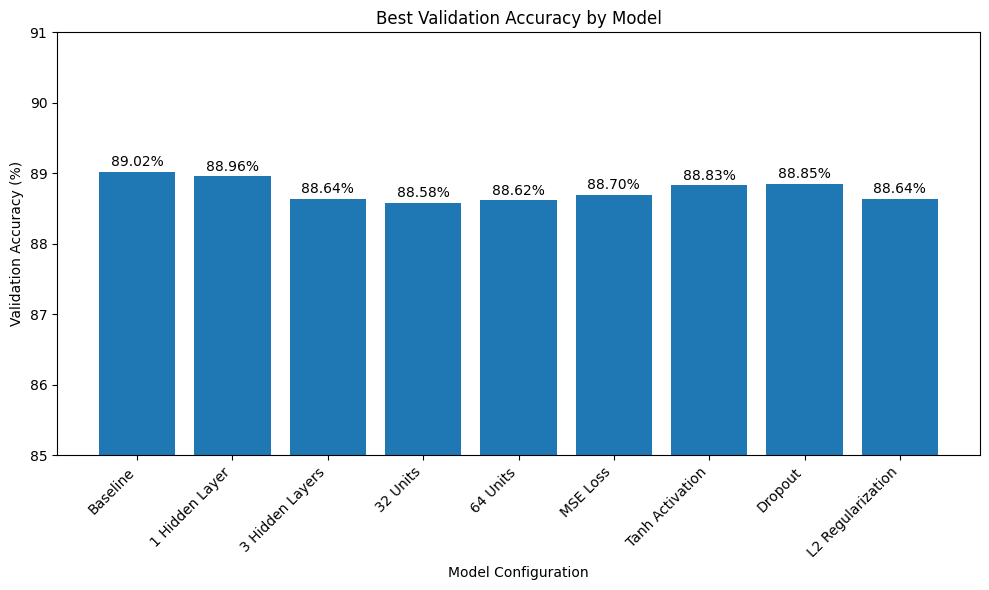

In [88]:
plt.figure(figsize=(10, 6))

bars = plt.bar(
    results["Model"],
    results["Best Validation Accuracy"] * 100
)

plt.title("Best Validation Accuracy by Model")
plt.xlabel("Model Configuration")
plt.ylabel("Validation Accuracy (%)")
plt.ylim(85, 91)
plt.xticks(rotation=45, ha="right")

for bar, accuracy in zip(bars, results["Best Validation Accuracy"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.08,
        f"{accuracy * 100:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

# Overall Validation Results
Validation accuracy was similar across all model configurations, ranging from approximately 88.6% to 89.0%. The baseline model, which used two hidden layers with 16 units per layer, ReLU activation, and binary crossentropy loss, achieved the highest observed validation accuracy at 89.02%. None of the tested modifications produced a higher peak validation accuracy. The relatively small differences across the models suggest that increasing model complexity or changing individual model settings did not substantially improve validation performance for this classification problem.

# Final Model Evaluation
Based on validation performance, the baseline configuration was selected for final evaluation. Because validation performance peaked at epoch 4, a new model using the baseline configuration will be trained for four epochs before evaluating its performance on the test data.

In [80]:
final_model = keras.Sequential([
    layers.Dense(16, activation="relu"),
    layers.Dense(16, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

final_model.compile(
    optimizer="rmsprop",
    loss="binary_crossentropy",
    metrics=["accuracy"])

In [81]:
final_model.fit(
    x_train,
    y_train,
    epochs=4,
    batch_size=512
)

Epoch 1/4
49/49 ━━━━━━━━━━━━━━━━━━━━ 4s 45ms/step - accuracy: 0.8232 - loss: 0.4715
Epoch 2/4
49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.8971 - loss: 0.2850
Epoch 3/4
49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.9186 - loss: 0.2230
Epoch 4/4
49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.9322 - loss: 0.1890


In [89]:
test_results = final_model.evaluate(x_test, y_test)

782/782 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8830 - loss: 0.2915


In [90]:
test_results

[0.2915107011795044, 0.8829600214958191]

# Final Test Results
The final model achieved a test accuracy of 88.30% with a test loss of 0.2915. This means that the model correctly classified approximately 88% of the previously unseen movie reviews as positive or negative. The test accuracy was slightly lower than the model's best validation accuracy of 89.02%, but the similar performance suggests that the model generalized reasonably well to unseen data.